<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/Qui%C3%B1onez_Kevin_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Kevin Angel Quiñonez Dominguez  

**Matrícula:** 271758

**Fecha:** 9 de octubre del 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [2]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico realizado a un cliente. (Nota: Un mismo cliente podría tener más de un contacto en el histórico). |
| ¿Qué se predice? |`y`: `Yes` si el cliente acepto un deposito a plazos, `No` si no lo acepto |
| ¿Qué tipo de problema es? |Clasificacion binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? |Antes de realizar la llamada al cliente. Se cuenta con su perfil demográfico (`age`, `job`, `marital`, etc.), su historial de campañas anteriores (`pdays`, `previous`, `poutcome`) e indicadores macroeconómicos (`euribor3m`, `cons.price.idx`, etc.). |
| ¿Qué columnas no deberían usarse como características y por qué? |`duration` y `campaign`. Ambas generan filtración de datos (data leakage) porque registran información que ocurre durante o después de la llamada. Usarlas causará un rendimiento falsamente perfecto en el entrenamiento, pero el modelo será inútil en la vida real porque no tendrá esos datos antes de llamar.  |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Espero que el porcentaje de contactos que terminó en contratación sea bajo, aproximadamente menos del 20%. Esto se debe a que las campañas de telemarketing bancario suelen tener tasas de conversión bajas, ya que la mayoría de los clientes tienden a rechazar productos financieros ofrecidos por teléfono de forma directa.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Posiblemente haya uno que otro `NaN` suelto por ahi, las columnas que pienso que pueden tener un `unknown` son:

*   `default`
*   `contact`
*   `y`



In [3]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.


print("Dimensiones del conjunto:")
print(df.shape)
print()

print("Tipos de dato por columna:")
print(df.dtypes)
print()

print("Tipos de dato por columna:")
print(df.nunique().sort_values())

Dimensiones del conjunto:
(41188, 21)

Tipos de dato por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Tipos de dato por columna:
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26
c

In [4]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.


print("Total valores NaN:") #No hay NaNs
print(df[df.isna().any(axis=1)])
print()


print("Columnas con valores 'unknown':")
print(df[df == "unknown"].count()[lambda x: x > 0])
print()


print("Porcentaje de 'unknown' por columna:")
print((df[df == "unknown"].count()[lambda x: x > 0] / len(df) * 100).round(2))
print()


# Cuenta las filas donde al menos una columna tiene "unknown"
print("Total de filas únicas con 'unknown':", (df == "unknown").any(axis=1).sum())
print("Porcentaje sobre el total:", round(((df == "unknown").any(axis=1).sum() / len(df) * 100),2))


Total valores NaN:
Empty DataFrame
Columns: [age, job, marital, education, default, housing, loan, contact, month, day_of_week, duration, campaign, pdays, previous, poutcome, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, y]
Index: []

Columnas con valores 'unknown':
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

Porcentaje de 'unknown' por columna:
job           0.80
marital       0.19
education     4.20
default      20.87
housing       2.40
loan          2.40
dtype: float64

Total de filas únicas con 'unknown': 10700
Porcentaje sobre el total: 25.98


In [5]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.

print("Filas duplicadas:")
print(df.duplicated().sum())
print(df[df.duplicated()])
print()

Filas duplicadas:
12
       age          job   marital            education  default housing loan    contact month day_of_week  duration  \
1266    39  blue-collar   married             basic.6y       no      no   no  telephone   may         thu       124   
12261   36      retired   married              unknown       no      no   no  telephone   jul         thu        88   
14234   27   technician    single  professional.course       no      no   no   cellular   jul         mon       331   
16956   47   technician  divorced          high.school       no     yes   no   cellular   jul         thu        43   
18465   32   technician    single  professional.course       no     yes   no   cellular   jul         thu       128   
20216   55     services   married          high.school  unknown      no   no   cellular   aug         mon        33   
20534   41   technician   married  professional.course       no     yes   no   cellular   aug         tue       127   
25217   39       admin.   m

In [6]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
print("Filas con pdays == 999:", df[df["pdays"] == 999].shape[0])
print("Porcentajes de filas con pdays == 999:",round((df[df["pdays"] == 999].shape[0] / len(df) * 100), 2))
print()

#  - una tabla de contingencia entre poutcome y (previous == 0),
print("Tabla de contingencia entre poutcome y (previous == 0):")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))
print()
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.
print("Tabla de contingencia entre poutcome y (pdays == 999):")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))
print()


Filas con pdays == 999: 39673
Porcentajes de filas con pdays == 999: 96.32

Tabla de contingencia entre poutcome y (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Tabla de contingencia entre poutcome y (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0



In [7]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print("Edad mínima:",df["age"].min(),"Edad máxima:",df["age"].max())
print()
#  - cuántas llamadas tienen duration igual a 0,
print("Llamadas con duracion igual a 0:",df[df["duration"] == 0].shape[0])
print()
#  - el mínimo y el máximo de campaign,
print("Campaign minimo:",df["campaign"].min(),"Campaign maxima:",df["campaign"].max()) #Numero de contactos minimo y maximo.
print()
#  - cuántas filas tienen previous negativo.
print("Filas con previous negativo:",df[df["previous"] < 0].shape[0]) #Numero de contactos antes de la campaña actual
print()




Edad mínima: 17 Edad máxima: 98

Llamadas con duracion igual a 0: 4

Campaign minimo: 1 Campaign maxima: 56

Filas con previous negativo: 0



**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

**Completitud:** Nulos implícitos bajo la categoría unknown en 6 variables (`job`, `marital`, `education`, `default`, `housing`, `loan`), esto impacta 10,700 registros o el 25.98% del dataset.

**Validez:** Falta de información explícita en el historial crediticio.  (`default = unknown`). Afecta 8,597 registros o 20.87% del dataset.

**Integridad** Marcador numérico 999 para representar "sin contacto previo" en la variable pdays. 39,673 registros o	96.32% del dataset.

**Unicidad** Registros idénticos duplicados en todas sus columnas.	12 registros o	0.03% del dataset

**Consistencia** Incongruencia entre `pdays = 999` (nunca contactado) y `poutcome != "nonexistent"` (resultado de campaña previa registrado). 1,000 registros o 2.43% del dataset.


**¿Cuales problemas dependen del significado de la variable** `y` **?**

**La variable** `duration` **(Data Leakage):**

La duración de la llamada se conoce únicamente después o durante la llamada en la que se decide `y`. Si `duration = 0`, entonces y siempre será "no". Si se incluyes `duration` en un modelo predictivo para llamadas futuras, el modelo tendrá una precisión inflada de forma irreal (target leakage), ya que antes de llamar a un cliente no sabes cuánto tiempo va a durar la llamada.


**La columna** `default` **(Riesgo de Crédito):**

La columna `default` indica si el cliente tiene créditos en mora. En el dataset solo hay 3 registros con `default = "yes"`, 32,588 con "no", y 8,597 como `"unknown"`. Para un banco, una persona en mora (`default = "yes"`) difícilmente será un candidato apto o contratante de un producto financiero. Tratar los 8,597 `"unknown"` como nulos ordinarios o imputarlos como `"no"` altera el perfil de riesgo de los clientes que aceptan la oferta (`y = "yes"`).

**Inconsistencias entre** `pdays` **y** `poutcome`:

`pdays = 999` indica que no hubo contacto previo, pero hay casos donde poutcome registra el éxito/fracaso de una campaña anterior.

La efectividad del telemarketing (`y`) está fuertemente correlacionada con el comportamiento del cliente en campañas pasadas. Convertir 999 a un valor numérico continuo (ej. $999$ días) deformará la escala de tiempo y distorsionará la probabilidad de conversión de `y`.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

`unknown` en `default` significa que se desconoce que a el cliente que se llamo si tiene credito en incumplimiento, lo cual tiene logica, no puedes saber si una persona tiene credito en incumplimiento en otro banco, a menos que fueran datos exclusivos de este



**Decisión:** Tratar `unknown` como una categoría explícita más.

**Justificación:** Un valor `unknown` indica que la institución bancaria no dispone del historial crediticio del cliente en otras entidades al momento del contacto. Es una limitación real de información, no un error de captura.

Eliminar estas filas implicaría desechar 8,597 registros (20.87% del dataset), lo que generaría un sesgo severo en la muestra y eliminaría información útil del resto de las variables.



## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

In [31]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
entrenamiento, prueba = train_test_split(df, test_size=0.2, random_state=42, stratify=df["y"])
ent = entrenamiento.copy()
ent["suscribe"] = entrenamiento["y"].apply(lambda x: 1 if x == "yes" else 0)
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
print("Tamaño de entrenamiento:", entrenamiento.shape)
print("Tamaño de prueba:", prueba.shape)
print()
#  - el porcentaje de contratación (y igual a yes) en cada uno.


print("Proporción de contratación en entrenamiento:")
print(entrenamiento["y"].value_counts(normalize=True))
print()

print("Proporción de contratación en prueba:")
print(prueba["y"].value_counts(normalize=True))
print()

print("Proporción de contratación en ent:")
print(ent["y"].value_counts(normalize=True))

Tamaño de entrenamiento: (32950, 21)
Tamaño de prueba: (8238, 21)

Proporción de contratación en entrenamiento:
y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64

Proporción de contratación en prueba:
y
no     0.887351
yes    0.112649
Name: proportion, dtype: float64

Proporción de contratación en ent:
y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64


**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [32]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

En mi prediccion mencione que seria menor al 20% total del dataset, algo vago pero efectivamente fue menor al 20%, siendo 11.26% aproximadamente.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Con este caso, seria dependiente del porcentaje de `no` que hay al respecto, ya que depende de la distribucion de los datos. Si hubiera 75% de no significa que es exacto esa cantidad de veces

Numero y porcentaje de clientes por clase en ent:
y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64

Razon entre clase mayoritaria y minoritaria:
7.876616379310344

Exactitud de responder siempre 'no': 0.89



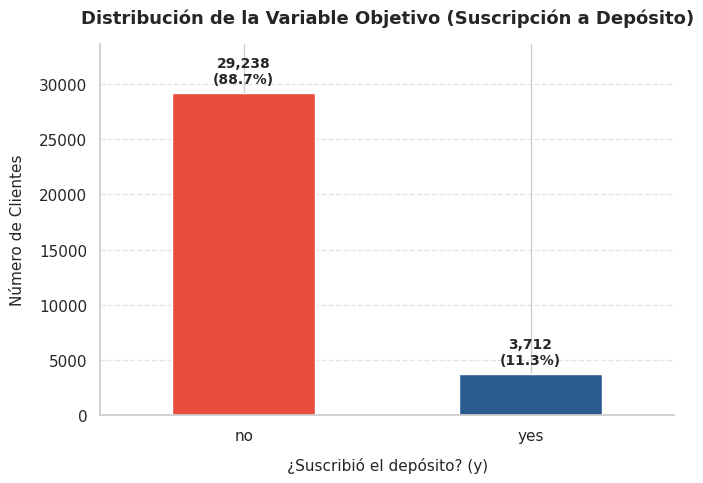

In [10]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
print("Numero y porcentaje de clientes por clase en ent:")
print(ent["y"].value_counts(normalize=True))
print()
#  - la razón entre la clase mayoritaria y la minoritaria,
print("Razon entre clase mayoritaria y minoritaria:")
print(ent["y"].value_counts(normalize=True).max() / ent["y"].value_counts(normalize=True).min())
print()
#  - la exactitud de responder siempre "no",
print("Exactitud de responder siempre 'no':", round(ent["y"].value_counts(normalize=True).max(), 2))
print()

#  - una gráfica de barras con el número de clientes por clase.

#Configurar figura y datos
fig, ax = plt.subplots(figsize=(7, 5))
counts = ent["y"].value_counts()
total = len(ent)

#Graficar barras con colores personalizados
colors = ['#e74c3c', '#2b5c8f']  # Rojo para 'no', azul para 'yes'
bars = counts.plot(kind="bar", color=colors, ax=ax, width=0.5, rot=0)

#Personalizar títulos y ejes
plt.title("Distribución de la Variable Objetivo (Suscripción a Depósito)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("¿Suscribió el depósito? (y)", fontsize=11, labelpad=10)
plt.ylabel("Número de Clientes", fontsize=11, labelpad=10)
plt.ylim(0, max(counts) * 1.15)  # Espacio para las etiquetas superiores

#Anotar valores y porcentajes sobre las barras
for bar in bars.patches:
    height = bar.get_height()
    percentage = (height / total) * 100
    ax.annotate(f'{height:,}\n({percentage:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

#Limpiar bordes estéticos
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

En la parte A se determino que el porcentaje de si seria menor a 20%.

En la parte D se determino para este caso que el porcentaje de no es 88.73%.

El hecho de que el 'No' represente el 88.73% confirma la predicción de la Parte A (donde se estimó un 'Sí' menor al 20%). Para la evaluación del modelo, esto implica que la métrica de exactitud (accuracy) no es confiable, ya que un modelo sin entrenar que siempre responda 'No' tendría un 88.73% de acierto basal. Por lo tanto, evaluar el éxito real del modelo implica utilizar métricas inmunes al desequilibrio de clases, tales como el F1-Score, la Precisión y el Recall, enfocadas en la capacidad del algoritmo para detectar el 11.27% de los casos 'Sí'.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Considero que seran `age`, `duration` y `cons.price.idx`

Mediana de cada variable numérica por clase de y:
      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1

Diagramas de caja por clase de y de al menos tres variables age, duration y cons.price.idx :
[<Axes: title={'center': 'age'}, xlabel='y'>
 <Axes: title={'center': 'duration'}, xlabel='y'>
 <Axes: title={'center': 'cons.price.idx'}, xlabel='y'>]


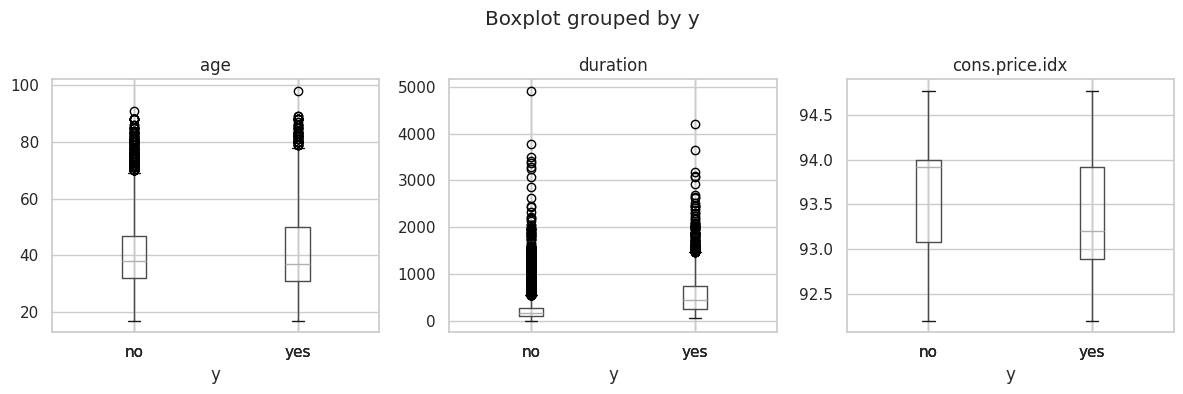

In [11]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
print("Mediana de cada variable numérica por clase de y:")
print(ent.groupby("y")[numericas].median())
print()
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas. Eligo age, duration y cons.price.idx
print("Diagramas de caja por clase de y de al menos tres variables age, duration y cons.price.idx :")
print(ent.boxplot(column=["age", "duration", "cons.price.idx"], by="y", sharey=False, layout=(1, 3), figsize=(12, 4)))
plt.tight_layout()
plt.show()


**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

`duration` (Separa fuertemente): Medianas: `no` = 164.0 segundos vs. `yes` = 448.0 segundos.La mediana de los clientes que aceptan el depósito (`yes`) es casi 3 veces mayor que la de quienes no aceptan (`no`). Las llamadas más largas están claramente asociadas a una decisión positiva (aunque, como ya vimos, presenta target leakage).

`age` (No separa):Medianas: no = 38.0 años vs. yes = 37.0 años. La diferencia entre medianas es de apenas 1 año. La edad central de ambos grupos es prácticamente idéntica, por lo que la mediana de esta variable no ayuda a discriminar si un cliente contratará o no.


`cons.price.idx` (No separa de forma relevante): Medianas: no = 93.918 vs. yes = 93.200. La diferencia entre medianas es de menos de 0.71 puntos (~0.76%). Las distribuciones están muy superpuestas, indicando que el índice de precios al consumidor por sí solo apenas varía entre ambas clases.





### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? `age`, `duration` y `pdays`

In [12]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
print("Limites de Tukey de cada variable de la lista numericas:")
print(ent[numericas].apply(lambda x: x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25))))
print()
print("Registros fuera de los limites de Tukey por variable:")
print(ent[numericas].apply(lambda x: ((x < x.quantile(0.25) - 1.5 * (x.quantile(0.75) - x.quantile(0.25)) ) | (x > x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25)))).sum()))

Limites de Tukey de cada variable de la lista numericas:
age                 69.5000
duration           643.0000
campaign             6.0000
pdays              999.0000
previous             0.0000
emp.var.rate         6.2000
cons.price.idx      95.3725
cons.conf.idx      -26.9500
euribor3m           10.3865
nr.employed       5421.6000
dtype: float64

Registros fuera de los limites de Tukey por variable:
age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.

`age`: Es totalmente normal que haya edades superiores a 69 años, ellos representan el segmento de la tercera edad en el mercado. No la eliminaria.

`duration`: Una llamada de mas de 10 minutos significa que el cliente realizo multiples preguntas que alargo la llamada. Es totalmente viable y real. No la eliminaria.

`campaign`: Representa a los clientes que mas se han contactado para ofrecer servicio. Los valores fuera de limite Reflejan el comportamiento operativo de la fuerza de ventas y la persistencia en el contacto. No la eliminaria.

`pdays`: Cualquier valor que difiera de pdays significa que fueron contactados recientemente. No la eliminaria.

`previous`: Eliminar cualquier registro atipico de esta columna eliminara contactos con clientes con los que hubo un contacto previo (previous > 0) No la eliminaria.

`cons.conf.idx`: Este valor representa el indice de confianza del consumidor, podria tratarse para recortarse o acotarse al valor percentil limite ya que es influenciado por crisis o recesiones extremas. No eliminar, pero tratar.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Por su naturaleza matemática, el logaritmo es mucho más potente que la raíz cuadrada para contraer colas largas, estabilizar la varianza y transformar el crecimiento exponencial de los datos en una distribución más simétrica (normal).

Tabla comparativa de Asimetría (Skewness):
          Original  Raíz Cuadrada (sqrt)  Logaritmo (log1p)
age         0.7608                0.4261             0.1324
duration    3.3266                1.2037            -0.4302
campaign    4.7425                2.1630             1.3510



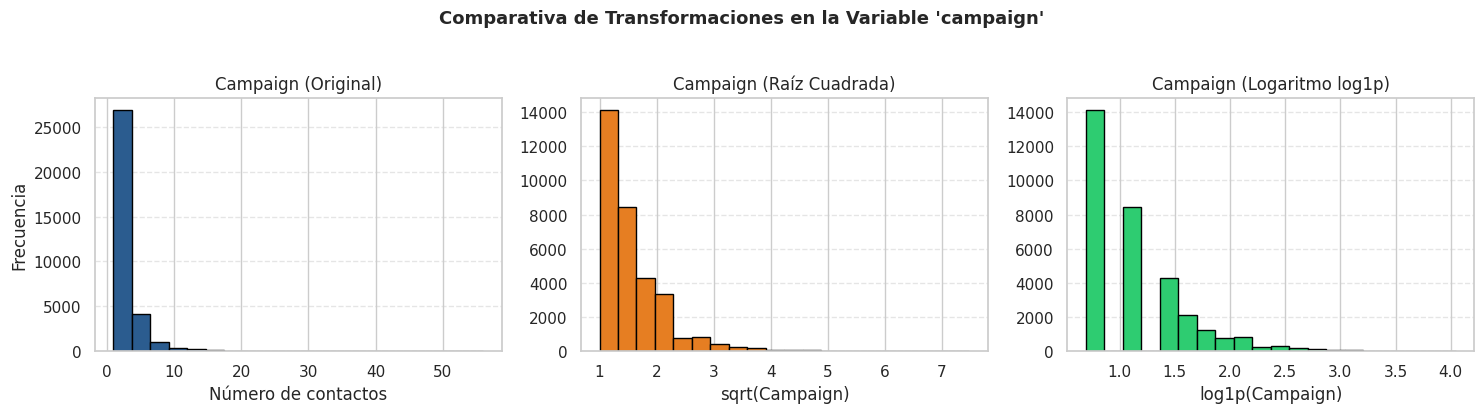

In [20]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

# Construir la tabla comparativa de asimetría (Skewness)

cols = ["age", "duration", "campaign"]
tabla_asimetria = pd.DataFrame({
    'Original': ent[cols].skew(),
    'Raíz Cuadrada (sqrt)': np.sqrt(ent[cols]).skew(),
    'Logaritmo (log1p)': np.log1p(ent[cols]).skew()
})

print("Tabla comparativa de Asimetría (Skewness):")
print(tabla_asimetria.round(4))
print()

# Graficar histogramas comparativos para 'campaign'
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Original
ent["campaign"].hist(ax=ax[0], color='#2b5c8f', bins=20, edgecolor='black')
ax[0].set_title("Campaign (Original)")
ax[0].set_xlabel("Número de contactos")
ax[0].set_ylabel("Frecuencia")

# Raíz Cuadrada
np.sqrt(ent["campaign"]).hist(ax=ax[1], color='#e67e22', bins=20, edgecolor='black')
ax[1].set_title("Campaign (Raíz Cuadrada)")
ax[1].set_xlabel("sqrt(Campaign)")

# Logaritmo (log1p)
np.log1p(ent["campaign"]).hist(ax=ax[2], color='#2ecc71', bins=20, edgecolor='black')
ax[2].set_title("Campaign (Logaritmo log1p)")
ax[2].set_xlabel("log1p(Campaign)")

# Limpiar cuadrículas y ajustar espacios
for a in ax:
    a.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Comparativa de Transformaciones en la Variable 'campaign'", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.


**Tipo de asimetría**: La variable original presenta una asimetría positiva pronunciada (sesgada hacia la derecha) con presencia de cola larga por contactos atípicos.   
**Transformación recomendada:** Logaritmo (np.log1p). Es la más efectiva porque reduce de forma sustancial la escala del sesgo, facilita la interpretación y mejora el rendimiento si se utilizan modelos lineales o redes neuronales.  

**Prediccion**:  Mi predicción coincidió debido a que el logaritmo (np.log1p) es matemáticamente más potente que la raíz cuadrada para contraer colas largas hacia la derecha. Al reducir de forma exponencial el impacto de los contactos atípicos (valores extremadamente altos), logró transformar la distribución asimétrica en una escala mucho más concentrada, simétrica y óptima para los modelos.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?

Espero que las variables catagoricas con mayor tasa de contratacion sean:

*   `job`
*   `education`
*   `contact`

Las variables que espero que casi no separen las clases son:

*   `default`
*   `loan`
*   `contact`





In [21]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.
print("Numero de categorias de cada variable de la lista categoricas:")
print(ent[categoricas].nunique())
print()
print("Tasa global de contratacion en ent:")
print(ent["y"].value_counts(normalize=True))

Numero de categorias de cada variable de la lista categoricas:
job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64

Tasa global de contratacion en ent:
y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64


In [29]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

print("Tabla con el número de clientes y la tasa de contratación (en %) de cada categoría de cada variable categórica:\n")

# Reestructurar directamente sobre 'ent' usando 'suscribe' (1 si y == 'yes', 0 si no)
largo = (
    ent[categoricas]
    .astype(str)
    .assign(suscribe=(ent["y"] == "yes").astype(int))
    .melt(id_vars="suscribe", var_name="caracteristica", value_name="categoria")
)

# Agrupar por característica y categoría para calcular el total de clientes y la tasa
tasas = largo.groupby(["caracteristica", "categoria"])["suscribe"].agg(
    clientes="count",
    tasa_contratacion="mean"
)

# Convertir la tasa a porcentaje (en %) y redondear
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

# ---------------------------------------------------------
# RESULTADOS SOLICITADOS
# ---------------------------------------------------------

# A. Las 12 categorías con mayor tasa de contratación
print("--- 12 Categorías con MAYOR tasa de contratación ---")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(12))
print("\n" + "="*60 + "\n")

# B. Las 8 categorías con menor tasa de contratación
print("--- 8 Categorías con MENOR tasa de contratación ---")
print(tasas.sort_values("tasa_contratacion", ascending=True).head(8))
print("\n" + "="*60 + "\n")

# C. Tablas de variables específicas: default, housing, loan y day_of_week
variables_especificas = ["default", "housing", "loan", "day_of_week"]

for var in variables_especificas:
    if var in tasas.index.levels[0]:
        print(f"--- Tasa de contratación según '{var}' ---")
        print(tasas.loc[var])
        print()




Tabla con el número de clientes y la tasa de contratación (en %) de cada categoría de cada variable categórica:

--- 12 Categorías con MAYOR tasa de contratación ---
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7


--- 8 Categorías con MENOR tasa de contratación ---
          

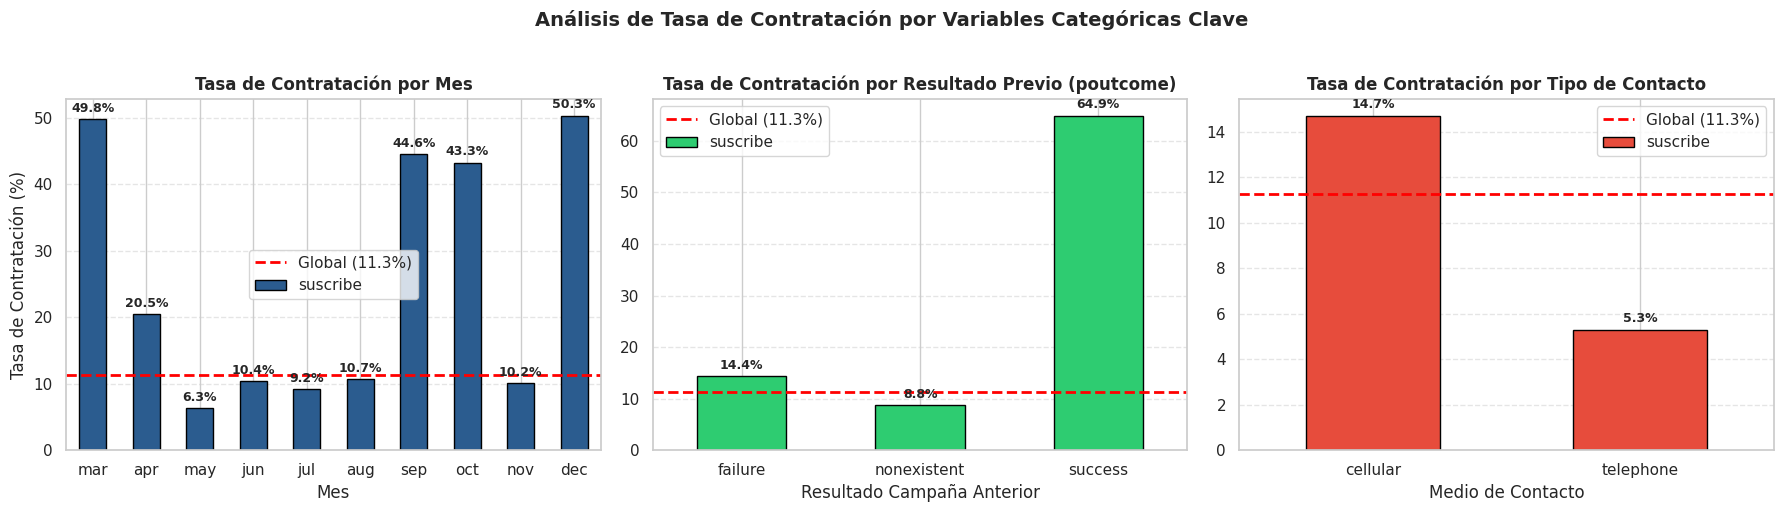

In [30]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.


# 1. Tasa de contratación global (en %) directamente desde 'ent'
tasa_global = (ent['y'] == 'yes').mean() * 100

# 2. Orden cronológico estricto de los meses
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

# 3. Configurar la figura con 3 subgráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ---------------------------------------------------------
# Subgráfico 1: Tasa por Mes (Month)
# ---------------------------------------------------------
tasa_month = (
    ent.assign(suscribe=(ent['y'] == 'yes') * 100)
    .groupby('month')['suscribe']
    .mean()
    .reindex(orden_meses)
)
tasa_month.plot(kind='bar', ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].axhline(tasa_global, color='red', linestyle='--', linewidth=2, label=f'Global ({tasa_global:.1f}%)')
axes[0].set_title("Tasa de Contratación por Mes", fontweight='bold')
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Tasa de Contratación (%)")
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for p in axes[0].patches:
    if not pd.isna(p.get_height()):
        axes[0].annotate(f"{p.get_height():.1f}%",
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# ---------------------------------------------------------
# Subgráfico 2: Tasa por Resultado Previo (Poutcome)
# ---------------------------------------------------------
tasa_poutcome = (
    ent.assign(suscribe=(ent['y'] == 'yes') * 100)
    .groupby('poutcome')['suscribe']
    .mean()
)
tasa_poutcome.plot(kind='bar', ax=axes[1], color='#2ecc71', edgecolor='black')
axes[1].axhline(tasa_global, color='red', linestyle='--', linewidth=2, label=f'Global ({tasa_global:.1f}%)')
axes[1].set_title("Tasa de Contratación por Resultado Previo (poutcome)", fontweight='bold')
axes[1].set_xlabel("Resultado Campaña Anterior")
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# ---------------------------------------------------------
# Subgráfico 3: Tasa por Tipo de Contacto (Contact)
# ---------------------------------------------------------
tasa_contact = (
    ent.assign(suscribe=(ent['y'] == 'yes') * 100)
    .groupby('contact')['suscribe']
    .mean()
)
tasa_contact.plot(kind='bar', ax=axes[2], color='#e74c3c', edgecolor='black')
axes[2].axhline(tasa_global, color='red', linestyle='--', linewidth=2, label=f'Global ({tasa_global:.1f}%)')
axes[2].set_title("Tasa de Contratación por Tipo de Contacto", fontweight='bold')
axes[2].set_xlabel("Medio de Contacto")
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend()
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.suptitle("Análisis de Tasa de Contratación por Variables Categóricas Clave", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.


La categoria con **mayor** tasa fue de `poutcome` con success con 1105 clientes y 64.9% de contratacion.

La categoria con **menor** tasa fue `default` con yes con 3 clientes y 0.0% de tasa de aceptacion .

Las variables que casi no separan clases son:



*   `loan` (Préstamo personal): Prácticamente nula separación. `no` = 11.3%, `unknown` = 11.3%, `yes` = 11.2%.   La diferencia es de 0.1%; tener o no un préstamo personal no cambia en nada la probabilidad de contratar.

*   `housing` (Crédito hipotecario): Casi nula separación. `no` = 10.9%, `unknown` = 11.3%, `yes` = 11.6%.   Todas sus categorías se mantienen alrededor del 11%.
*    `day_of_week` (Día de la semana de contacto): Muy baja separación. Varía de 10.2% (mon) a 12.0% (thu).   Llamar un lunes o un jueves ofrece casi exactamente el mismo rendimiento.

Las variables catagoricas con mayor tasa de contratacion que crei fueron

*   `job` la cual fue el top 6 (`student`) y 7 (`retired`) de los 12
*   `education` fue top 9 (`illiterate`) y 11 (`unknown`)
*   `contact` fue top 12 (`cellular`)

Las variables que crei que casi no separen las clases son:

*   `default`
*   `loan`
*   `contact`

De las cuales solamente loan mostro que no habia separacion de clases.



**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.


**¿Qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`?**
La omisión del dato no es un simple descuido; representa un patrón de comportamiento implícito.  La disposición a aceptar el producto se reduce a menos de la mitad cuando la variable es `unknown` (5.2%) comparado con cuando es `no` (12.9%).   Un cliente que no proporciona o del cual se desconoce su historial de crédito responde de forma muy diferente a uno que confirma no estar en mora. Esto hace inviable imputar esos datos debido a que es un comportamiento completamente diferente y engañaría al modelo respecto a la verdadera probabilidad de conversión.

**¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?**

Ambos tienen una alta taza de aceptacion a pesar de la pequeña cantidad de clientes representan un riesgo de tamaño muestral extremo. La muestra de `default`es de solo 3 clientes con una tasa de aceptacion de 0.0% cualquier partición aleatoria de datos (train/test split) o validación cruzada puede dejar este valor en un solo bloque o generar divisiones vacías. La muestra de
`illiterate` son 16 clientes con una tasa de aceptacion de 18.8%, lo que a medidas cuentas dice que aceptaron 3 clientes que no saben leer. La tasa parece ser "alta" en el ranking, pero estadísticamente no es confiable para extrapolar a la población general debido al escaso volumen de datos.



## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

`emp.var.rate` y `cons.price.idx` (Variacion del empleo e indice de precios)

`euribor3m` y `cons.price.idx` (Tasa euribor a 3 meses e indice de precios)

`emp.var.rate` y `euribor3m` (Variacion del empleo y tasa euribor a 3 meses)

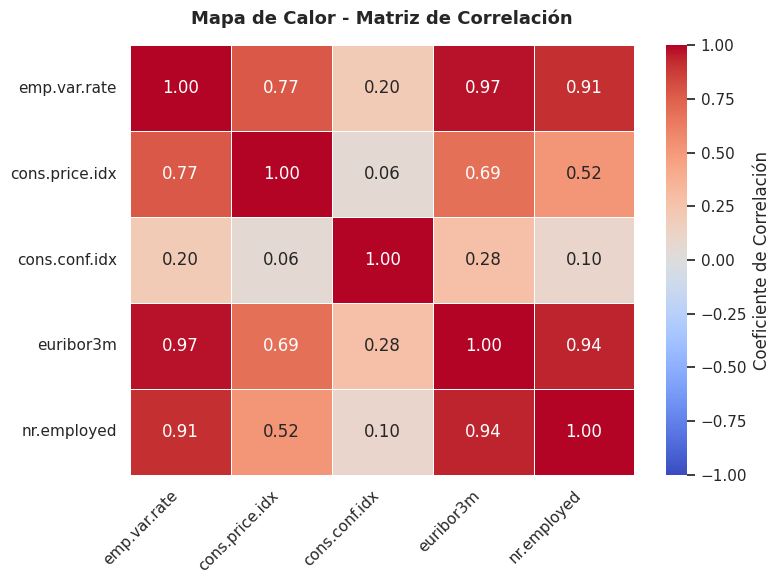

In [27]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

#Calcular la matriz de correlación
matriz_corr = ent[macro].corr()

#Configurar el tamaño de la figura
plt.figure(figsize=(8, 6))

#Crear el mapa de calor
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente de Correlación"}
)


plt.title("Mapa de Calor - Matriz de Correlación", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right') # Inclina las etiquetas del eje X para mejor lectura
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

*   `emp.var.rate` y `euribor3m` (Variacion del empleo y tasa euribor a 3 meses)
*   `nr.employed` y `euribor3m`    (Numero de empleado y tasa euribor a 3 meses)
*   `nr.employed` y `emp.var.rate` (Numero de empleado y Variacion del empleo)

La altísima correlación entre `emp.var.rate`, `euribor3m` y `nr.employed` confirma multicolinealidad severa. Para evitar redundancia de datos e inestabilidad en los coeficientes del modelo, la decisión técnica recomendada es seleccionar una sola variable representativa como `euribor3m`.



### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [25]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
print("Resumen estadistico de duration por clase de y:")
print(ent.groupby("y")["duration"].describe())
print()

Resumen estadistico de duration por clase de y:
       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0



**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

No la incluiria.

La variable duration mide la duración de la llamada en segundos, un dato que se conoce únicamente durante o después de realizar el contacto con el cliente. En un modelo prospectivo diseñado para seleccionar a quién llamar antes de realizar la marcación, es un valor del futuro que resulta imposible de conocer de antemano, tambien como se observó en el análisis de medianas (164s para no vs. 448s para yes), existe una correlación casi directa entre llamadas muy largas y la aceptación del depósito. Incluirla provocaría que el modelo aprenda un patrón "tramposo" e irreal, mostrando una precisión falsamente alta durante el entrenamiento pero siendo completamente inútil en producción.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

Podria causar una fuga de datos temporal al dividir al azar, el conjunto de entrenamiento (Train) podra contener registros del futuro (ej. datos de octubre) y el conjunto de evaluación (Test) tendria registros del pasado (ej. datos de marzo). El modelo aprenderá utilizando información del "futuro" para predecir el "pasado", lo cual es imposible de replicar en un entorno real.

Tambien podria generar una aproximacion irreal de desempeño dado que los indicadores macroeconómicos (`euribor3m`, `emp.var.rate`, `cons.price.idx`) están fuertemente ligados a la fecha del registro, un Random Split hace que el conjunto de entrenamiento y el de prueba compartan exactamente el mismo contexto económico subyacente. La métrica de evaluación en Test será engañosamente alta, pero el modelo fallará cuando se aplique en campañas futuras si las condiciones macroeconómicas (como las tasas de interés o la inflación) han cambiado.



## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|Proporción de negarse a contratación en entrenamiento (`y`) es de 88.73%  | Usar métricas orientadas a clase minoritaria (Recall, F1-Score, ROC-AUC) y considerar balanceo | Parte D1 |
| La variable duration genera target leakage (alta correlación con `y = yes` en llamadas de más de 448s vs 164s). | Eliminar la variable del conjunto de predicción previa al contacto. | Parte D2 Y F2 |
|Presencia de 25.98% de filas con al menos un marcador `unknown` en variables categóricas. | Mantener "unknown" como una categoría explícita más (no imputar ni borrar filas). | Parte B2  |
|96.32% de los registros tienen `pdays = 999` ("sin contacto previo").| Convertir a variable categórica o binaria (contactado_previamente: 0 / 1).| Parte B4 |
|Alta correlación (`r > 0.90`) entre indicadores macroeconómicos (`emp.var.rate, euribor3m, nr.employed`). |Conservar solo una variable representativa (preferentemente euribor3m) o aplicar PCA para evitar multicolinealidad.| Parte F1|
|12 filas duplicadas exactas identificadas en el dataset. |Eliminar los registros duplicados.|Parte B3 |
| La categoría `poutcome = success` alcanza una tasa de contratación del 64.9% (vs. 11.3% global), representando la variable categórica con mayor poder predictivo individual.|Conservar poutcome como variable prioritaria y agrupar o codificar de forma ordinal manteniendo el alto impacto de la conversión previa. | Parte E2 |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

Las parte A (Definicion del problema), parte B (Descripción de los datos y detección de problemas de calidad, conjunto total) y parte C (Division en entrenamiento y prueba) se hicieron con todo el dataset.

Las partes D (Exploracion del objetivo y de las variables numericas),E (Exploracion de las variables categoricas) ,F (Relaciones entre caracteristicas y variable duration),G(Hoja de decisiones y justificacion de uso de los datos)  se hicieron con los datos de entrenamiento.

Las etapas de auditoría inicial y división (A, B y C) se realizan sobre el dataset completo para conocer la estructura técnica general del insumo. Por el contrario, la exploración detallada y la toma de decisiones metodológicas (D, E, F y G) se restringen estrictamente al conjunto de entrenamiento (ent) para prevenir la fuga de información (Data Leakage) y garantizar que el conjunto de prueba funcione como una validación 100% imparcial y realista del comportamiento del modelo en producción.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

Explorar el conjunto de prueba sesgaría decisiones como el ajuste de umbrales por desbalance de clases, la selección de características (como la eliminación de variables no discriminantes) y el tratamiento de categorías raras o nulos.

En la evaluación final, esto se reflejaría como una métrica de evaluación (F1-Score / ROC-AUC) sobreestimada y falsamente optimista, provocando que el modelo falle al ser aplicado en campañas de telemarketing reales en el futuro.